# Robustness of the combined parametrization against the data source

**Purpose.** The combined reference system (SI, section 8.4) pools rate constants from this work and from the literature.
For the 23 reactions measured by both, the literature values are on average 0.42 lg units higher. This notebook
(i) resolves that offset by nucleophile class and records how the residual pruning of the selection treats every
overlapping measurement, and (ii) tests how the parametrized scale changes when either source is given precedence for
the overlapping reactions (source swap).

**Scope.** The raw combined input (278 rate constants), the reference system of the full parametrization and its
parameters with 95 % bootstrap intervals are read from the metadata workbook of the full LFER analysis
(`lfer_analysis_v2_metadata.xlsx`). The fitting engine (`fit_lfer`, `predict_lgk`) and the automated selection (coverage
rules and iterative residual pruning, `automated_core`) are identical to those of the full analysis; the notebook first
verifies that they reproduce the full parametrization exactly. 

**Source-swap variants.** In "this work decides", the overlapping literature values are removed from the raw input, so
that every duplicated reaction is represented by the value from this work only; in "literature decides", the overlapping
values from this work are removed. The swap is applied to the 19 overlapping nucleophile reactions; the four overlapping
hydrolysis reactions (five literature values) are left as in the full parametrization (both values in the input, the pruning decides). 
All other measurements are unchanged, and the complete selection is rerun for each variant. Compared are the composition of the 
reference system, the reactivity parameters (relative to the half-width of the 95 % interval of the full parametrization) and the 
predicted rate constants for all combinations of species that are parametrized in both. The $E_\mathrm{P}$ values of the 
20 phosphorylating agents defined by hydrolysis alone are recomputed from each variant's water parameters, $(\lg k - N_\mathrm{P}(\mathrm{water}))/s_\mathrm{N,P}(\mathrm{water})$, as in the full analysis; the ten nucleophiles attached to the fixed scale afterwards are not re-placed.

**Outputs.** `lfer_analysis_swap_offset.png`, `lfer_analysis_swap_parameters.png`, `lfer_analysis_swap_results.xlsx`.

## 0. Configuration

In [5]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

FONTSIZE = 12
mpl.rcParams.update({
    "font.family": "Arial", "font.size": FONTSIZE,
    "axes.titlesize": FONTSIZE, "axes.labelsize": FONTSIZE,
    "xtick.labelsize": FONTSIZE, "ytick.labelsize": FONTSIZE, "legend.fontsize": FONTSIZE,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4, "ytick.major.size": 4, "axes.linewidth": 0.9,
    "figure.dpi": 110, "savefig.dpi": 150,
})


class CONFIG:
    # --- input: metadata workbook of the full LFER analysis ---
    V2_METADATA_FILE = "lfer_analysis_v2_metadata.xlsx"
    RAW_SHEET = "combined_raw_input"              # all 278 rate constants of both sources
    REFERENCE_SHEET = "selected_dataset"          # the 187 rate constants of the reference system
    PARAMS_SHEET = "params_core_bootstrap"        # point estimates and 95 % intervals of the 84 parameters
    HYDROLYSIS_E_SHEET = "discarded_E_fit_rows"   # water rate constants behind the 20 hydrolysis-only E_P values
    HYDROLYSIS_E_CI_SHEET = "discarded_E_placements"  # their E_P with 95 % intervals

    # --- output ---
    OFFSET_FIG_FILE = "lfer_analysis_swap_offset.png"
    SWAP_FIG_FILE = "lfer_analysis_swap_parameters.png"
    RESULTS_FILE = "lfer_analysis_swap_results.xlsx"

    # --- labels ---
    SOURCE_THIS_WORK = "hte_kinetics"             # source label of this work in the workbook
    SOURCE_LITERATURE = "literature"
    WATER_LABEL = "water"
    FULL_LABEL = "full parametrization"
    VARIANTS = ("this work decides", "literature decides")

    # --- model form and anchoring (identical to the full parametrization) ---
    ANCHOR_NUC = "3,4-lutidine"   # reference nucleophile: s_N,P = 1; N_P is fitted
    ANCHOR_ELEC = "P7"            # reference electrophile: E_P = 0

    # --- automated selection (identical to the full parametrization) ---
    MIN_ELECTROPHILES = 3         # a nucleophile enters a refit only with >=3 electrophiles
    MIN_NUC_PER_ELEC = 2          # a jointly fitted electrophile needs >=2 distinct nucleophiles
    OUTLIER_MAD_K = 2.5           # flag reaction as outlier if |resid| > k * sigma_MAD

    # --- least-squares bounds (identical to the full parametrization) ---
    S_BOUNDS = (0.0, 1.5); N_BOUNDS = (-60.0, 60.0); E_BOUNDS = (-60.0, 60.0)

    # --- nucleophile classes for the offset analysis ---
    CLASS_PATTERNS = {
        "pyridine": ("pyridine", "lutidine", "picoline", "collidine", "nicotinamide", "nicotinicacid", "nicotinic acid"),
        "azole": ("imidazole", "pyrazole", "triazole"),
        "thiol": ("thiol", "cystein", "mercapto", "glutathione", "thioglycolate", "thioacetic"),
        "phenol": ("phenol", "phenoxide", "phenolate"),
        "aliphatic amine": ("amine", "piperidine", "pyrrolidine", "morpholine", "piperazine", "glycin", "ammonia",
                            "quinuclidine", "dabco", "triethylenediamine", "hydrazine", "hydroxylamine", "aminoacetonitrile"),
    }

    TOLERANCE_REPRODUCTION = 1e-3  # max. allowed deviation (lg units) from the full parametrization

## 1. Raw combined input and reference system of the full parametrization

Electrophiles are identified by their `P` identifier (the species key of the fit), nucleophiles by name. Duplicate
measurements of the same combination are separate rows, as in the full parametrization.

In [6]:
def read_rows(sheet):
    t = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=sheet)
    return pd.DataFrame({"nucleophile": t["nucleophile"].astype(str), "nucleophile_id": t["nucleophile_id"].astype(str),
                         "electrophile": t["electrophile_id"].astype(str), "source": t["source"].astype(str), "lgk": t["lgk"].astype(float)})

raw = read_rows(CONFIG.RAW_SHEET)
raw.insert(0, "rxn_id", np.arange(len(raw)))
ref_full = read_rows(CONFIG.REFERENCE_SHEET)

params_full_published = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.PARAMS_SHEET)
params_full_published["species"] = np.where(params_full_published["type"] == "electrophile",
                                            params_full_published["species_id"].astype(str), params_full_published["species"].astype(str))
params_full_published = params_full_published[["type", "species", "parameter", "point", "lo95", "hi95"]]

hydro_rows = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.HYDROLYSIS_E_SHEET)
hydro_rows = (hydro_rows[hydro_rows["nucleophile"].astype(str) == CONFIG.WATER_LABEL]
              .rename(columns={"electrophile_id": "electrophile", "E_fit": "E_full"})[["electrophile", "lgk", "E_full"]])
hydro_rows["electrophile"] = hydro_rows["electrophile"].astype(str)
hydro_ci = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.HYDROLYSIS_E_CI_SHEET).rename(columns={"electrophile_id": "electrophile"})
hydro_ci["electrophile"] = hydro_ci["electrophile"].astype(str)
hydro_ci = hydro_ci.set_index("electrophile")[["lo95", "hi95"]]

print(f"Raw combined input: {len(raw)} rate constants, {raw.nucleophile.nunique()} nucleophiles, {raw.electrophile.nunique()} phosphorylating agents; "
      f"sources: {raw.source.value_counts().to_dict()}")
print(f"Reference system of the full parametrization: {len(ref_full)} rate constants, {ref_full.nucleophile.nunique()} nucleophiles, "
      f"{ref_full.electrophile.nunique()} phosphorylating agents")
print(f"Phosphorylating agents defined by hydrolysis alone: {hydro_rows.electrophile.nunique()} ({len(hydro_rows)} water rate constants)")

Raw combined input: 278 rate constants, 59 nucleophiles, 34 phosphorylating agents; sources: {'literature': 176, 'hte_kinetics': 102}
Reference system of the full parametrization: 187 rate constants, 35 nucleophiles, 14 phosphorylating agents
Phosphorylating agents defined by hydrolysis alone: 20 (21 water rate constants)


## 2. LFER fitting engine and automated selection

`fit_lfer` and `predict_lgk` are identical to the full analysis: bounded least squares for
$\lg k_2 = s_{N,P} \cdot E_P + N_P$ with $s_{N,P}(\mathrm{Nu5}) = 1$ and $E_P(\mathrm{P7}) = 0$. `automated_core` is the
selection procedure of SI section 8.1: coverage pruning (a nucleophile needs at least three phosphorylating agents, a
phosphorylating agent at least two nucleophiles), then iterative removal of the measurement with the largest robust
residual (|residual − median| > 2.5 σ$_\mathrm{MAD}$) with refitting until no outlier remains. The source of a
measurement does not enter any decision.

In [7]:
def fit_lfer(data, cfg=CONFIG, anchor_nuc=None, anchor_elec=None, weights=None):
    anchor_nuc = anchor_nuc or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    d = data.reset_index(drop=True)
    nucs, elecs = sorted(d["nucleophile"].unique()), sorted(d["electrophile"].unique())
    if anchor_nuc not in nucs:
        raise ValueError(f"anchor nucleophile {anchor_nuc!r} not in data")
    if anchor_elec not in elecs:
        raise ValueError(f"anchor electrophile {anchor_elec!r} not in data")

    y, ni, ei = d["lgk"].to_numpy(), d["nucleophile"].to_numpy(), d["electrophile"].to_numpy()
    sw = np.sqrt(np.ones(len(d)) if weights is None else np.asarray(weights, float))
    E0 = {e: d.loc[d.electrophile == e, "lgk"].mean() for e in elecs}
    E0_anchor = E0[anchor_elec]

    free_s_n = [n for n in nucs if n != anchor_nuc]
    free_e = [e for e in elecs if e != anchor_elec]
    sdx = {n: k for k, n in enumerate(free_s_n)}
    ndx = {n: k for k, n in enumerate(nucs)}
    edx = {e: k for k, e in enumerate(free_e)}
    ns, nn, ne = len(free_s_n), len(nucs), len(free_e)

    N0 = []
    for n in nucs:
        at_anchor_e = d[(d["nucleophile"] == n) & (d["electrophile"] == anchor_elec)]["lgk"]
        N0.append(float(at_anchor_e.mean() if len(at_anchor_e) else d.loc[d.nucleophile == n, "lgk"].mean()))
    x0 = np.r_[np.ones(ns), N0, [E0[e] - E0_anchor for e in free_e]]
    lo = np.r_[np.full(ns, cfg.S_BOUNDS[0]), np.full(nn, cfg.N_BOUNDS[0]), np.full(ne, cfg.E_BOUNDS[0])]
    hi = np.r_[np.full(ns, cfg.S_BOUNDS[1]), np.full(nn, cfg.N_BOUNDS[1]), np.full(ne, cfg.E_BOUNDS[1])]
    x0 = np.clip(x0, lo + 1e-9, hi - 1e-9)

    is_anchor_n = (ni == anchor_nuc)
    is_anchor_e = (ei == anchor_elec)
    s_pos = np.array([sdx.get(n, 0) for n in ni])
    n_pos = np.array([ndx[n] for n in ni])
    e_pos = np.array([edx.get(e, 0) for e in ei])

    def resid(x):
        s, N, E = x[:ns], x[ns:ns+nn], x[ns+nn:]
        sv = np.where(is_anchor_n, 1.0, s[s_pos])
        Ev = np.where(is_anchor_e, 0.0, E[e_pos])
        Nv = N[n_pos]
        return sw * (sv * Ev + Nv - y)

    res = least_squares(resid, x0, bounds=(lo, hi), method="trf", max_nfev=30000)
    s, N, E = res.x[:ns], res.x[ns:ns+nn], res.x[ns+nn:]
    rows = []
    for k, n in enumerate(nucs):
        rows.append(dict(type="nucleophile", species=n, parameter="N", estimate=N[k]))
        rows.append(dict(type="nucleophile", species=n, parameter="s",
                         estimate=1.0 if n == anchor_nuc else s[sdx[n]]))
    rows.append(dict(type="electrophile", species=anchor_elec, parameter="E", estimate=0.0))
    for k, e in enumerate(free_e):
        rows.append(dict(type="electrophile", species=e, parameter="E", estimate=E[k]))

    params = pd.DataFrame(rows)
    fitted = _apply_params(d, params)
    r = fitted["residual"].to_numpy(); yv = fitted["lgk"].to_numpy()
    ss_res, ss_tot = float(np.sum(r**2)), float(np.sum((yv - yv.mean())**2))
    metrics = dict(n=len(d), n_nuc=len(nucs), n_elec=len(elecs),
                   rmse=float(np.sqrt(np.mean(r**2))), mae=float(np.mean(np.abs(r))),
                   r2=(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan, success=bool(res.success))
    return params, fitted, metrics, res


def _param_lookup(params):
    return params.set_index(["type", "species", "parameter"])["estimate"].to_dict()

def predict_lgk(params, nucleophile, electrophile):
    p = _param_lookup(params) if isinstance(params, pd.DataFrame) else params
    N = p[("nucleophile", nucleophile, "N")]
    E = p[("electrophile", electrophile, "E")]
    return N + p[("nucleophile", nucleophile, "s")] * E

def _apply_params(data, params):
    p = _param_lookup(params)
    out = data.copy()
    out["lgk_calc"] = [predict_lgk(p, n, e) for n, e in zip(data["nucleophile"], data["electrophile"])]
    out["residual"] = out["lgk"] - out["lgk_calc"]
    return out


def prune_coverage(data, cfg=CONFIG):
    "Iteratively enforce the coverage rules while preserving the two anchor species."
    d = data.copy(); dropped = []
    while True:
        before = len(d)
        cnt_n = d.groupby("nucleophile")["electrophile"].nunique()
        bad_n = [n for n in cnt_n.index if n != cfg.ANCHOR_NUC and cnt_n[n] < cfg.MIN_ELECTROPHILES]
        if bad_n:
            dropped += [("nucleophile<min_elec", n) for n in bad_n]
            d = d[~d["nucleophile"].isin(bad_n)]
        cnt_e = d.groupby("electrophile")["nucleophile"].nunique()
        bad_e = [e for e in cnt_e.index if e != cfg.ANCHOR_ELEC and cnt_e[e] < cfg.MIN_NUC_PER_ELEC]
        if bad_e:
            dropped += [("electrophile<min_nuc", e) for e in bad_e]
            d = d[~d["electrophile"].isin(bad_e)]
        d = d.reset_index(drop=True)
        if len(d) == before:
            break
    return d, dropped


def automated_core(data, cfg=CONFIG):
    "Coverage pruning, then iterative removal of the largest robust outlier with refitting (SI, section 8.1)."
    d, dropped = prune_coverage(data, cfg)
    removed = [dict(reason=kind, item=item, source=None, residual=None, rxn_id=None) for kind, item in dropped]
    while True:
        params, fitted, metrics, _ = fit_lfer(d, cfg)
        r = fitted["residual"].to_numpy(float)
        med = np.median(r)
        sig = 1.4826 * np.median(np.abs(r - med))
        if sig <= 1e-9:
            break
        z = np.abs(r - med) / sig
        j = int(np.argmax(z))
        if z[j] <= cfg.OUTLIER_MAD_K:
            break
        row = fitted.iloc[j]
        removed.append(dict(reason="MAD_outlier", item=f"{row['nucleophile']} / {row['electrophile']}", source=row["source"],
                            residual=float(row["residual"]), rxn_id=int(row["rxn_id"])))
        d = d.drop(index=d.index[j]).reset_index(drop=True)
        d, dropped_now = prune_coverage(d, cfg)
        removed += [dict(reason=kind, item=item, source=None, residual=None, rxn_id=None) for kind, item in dropped_now]
    params, fitted, metrics, _ = fit_lfer(d, cfg)
    return d, params, fitted, metrics, pd.DataFrame(removed)


def hydrolysis_only_E(params):
    "E_P of the phosphorylating agents defined by hydrolysis alone: mean over their water rate constants of (lg k - N_water)/s_water."
    p = _param_lookup(params)
    Nw, sw_ = p[("nucleophile", CONFIG.WATER_LABEL, "N")], p[("nucleophile", CONFIG.WATER_LABEL, "s")]
    return ((hydro_rows["lgk"] - Nw) / sw_).groupby(hydro_rows["electrophile"]).mean()


def run_selection(data, label):
    "Automated selection and joint refit on one input; returns everything the comparison needs."
    core, params, fitted, metrics, removed = automated_core(data)
    return dict(label=label, n_input=len(data), core=core, params=params, fitted=fitted, metrics=metrics, removed=removed,
                E_hydro=hydrolysis_only_E(params))

## 3. Reproduction of the full parametrization

The selection is run once on the complete raw input. The reference system must coincide with that of the full
parametrization (the same 187 measurements), and the parameters and the hydrolysis-derived $E_\mathrm{P}$ values must
agree with the full parametrization to numerical tolerance; otherwise the notebook stops.

In [8]:
full = run_selection(raw, CONFIG.FULL_LABEL)
m = full["metrics"]
print(f"Selection on the complete input: {m['n']} rate constants, {m['n_nuc']} nucleophiles, {m['n_elec']} phosphorylating agents, "
      f"RMSE = {m['rmse']:.4f}, R2 = {m['r2']:.4f}")

key = ["nucleophile", "electrophile", "source", "lgk"]
same_rows = full["core"][key].sort_values(key).reset_index(drop=True).round(9).equals(ref_full[key].sort_values(key).reset_index(drop=True).round(9))
cmp = full["params"].merge(params_full_published, on=["type", "species", "parameter"], how="left")
dev_par = float(np.nanmax(np.abs(cmp["estimate"] - cmp["point"])))
dev_hydro = float(np.max(np.abs(full["E_hydro"] - hydro_rows.groupby("electrophile")["E_full"].first().reindex(full["E_hydro"].index))))
print(f"Reference system identical: {same_rows}; max. deviation of the parameters: {dev_par:.1e} ({int(cmp['point'].isna().sum())} unmatched); "
      f"of the hydrolysis-derived E_P: {dev_hydro:.1e}")
if not same_rows or dev_par > CONFIG.TOLERANCE_REPRODUCTION or cmp["point"].isna().any() or dev_hydro > CONFIG.TOLERANCE_REPRODUCTION:
    raise RuntimeError("The full parametrization is not reproduced; check the input sheets and the selection procedure.")
print("Full parametrization reproduced.")

core_ids = set(full["core"]["rxn_id"])
ci_half = cmp.assign(ci_half=(cmp["hi95"] - cmp["lo95"]) / 2).set_index(["type", "species", "parameter"])["ci_half"]

Selection on the complete input: 187 rate constants, 35 nucleophiles, 14 phosphorylating agents, RMSE = 0.1404, R2 = 0.9953
Reference system identical: True; max. deviation of the parameters: 1.6e-08 (0 unmatched); of the hydrolysis-derived E_P: 2.1e-08
Full parametrization reproduced.


## 4. Overlapping measurements

For each reaction measured by both sources, the offset $\Delta = \lg k_2(\text{literature}) - \lg k_2(\text{this work})$ is
computed and the fate of each value in the selection is recorded (retained in the reference system, or removed by the
residual pruning). The offset is summarized by nucleophile class; the residual source bias of the reference fit is reported.

In [9]:
def nucleophile_class(name):
    n = str(name).lower()
    if n == CONFIG.WATER_LABEL:
        return "water"
    for cls, patterns in CONFIG.CLASS_PATTERNS.items():
        if any(k in n for k in patterns):
            return cls
    return "other"

pairs = lambda df: pd.Series(list(zip(df["nucleophile"], df["electrophile"])), index=df.index)
own_pairs = set(pairs(raw[raw.source == CONFIG.SOURCE_THIS_WORK])); lit_pairs = set(pairs(raw[raw.source == CONFIG.SOURCE_LITERATURE]))
dup_pairs = own_pairs & lit_pairs
dup = raw[pairs(raw).isin(dup_pairs)].assign(fate=lambda d: np.where(d["rxn_id"].isin(core_ids), "retained", "pruned"))

rows = []
for (n, e), g in dup.groupby(["nucleophile", "electrophile"]):
    h = g[g.source == CONFIG.SOURCE_THIS_WORK]; l = g[g.source == CONFIG.SOURCE_LITERATURE]
    for _, rl in l.iterrows():
        rows.append(dict(nucleophile=n, nucleophile_id=g["nucleophile_id"].iloc[0], electrophile=e, nucleophile_class=nucleophile_class(n),
                         lgk_this_work=float(h["lgk"].mean()), lgk_literature=float(rl["lgk"]), delta=float(rl["lgk"] - h["lgk"].mean()),
                         fate_this_work=" / ".join(sorted(set(h["fate"]))), fate_literature=rl["fate"],
                         retained_in_both=bool((h["fate"] == "retained").all() and rl["fate"] == "retained")))
duplicates = pd.DataFrame(rows).sort_values(["nucleophile_class", "delta"]).reset_index(drop=True)
assert not (duplicates["nucleophile_class"] == "other").any(), "unclassified nucleophile among the duplicates"

retained = duplicates[duplicates["retained_in_both"]]
summary_rows = [dict(subset=c, n=len(g), mean=g["delta"].mean(), median=g["delta"].median(), min=g["delta"].min(), max=g["delta"].max(),
                     n_retained_in_both=int(g["retained_in_both"].sum()))
                for c, g in duplicates.groupby("nucleophile_class", sort=False)]
summary_rows.sort(key=lambda r: -r["mean"])
summary_rows += [dict(subset="all", n=len(duplicates), mean=duplicates["delta"].mean(), median=duplicates["delta"].median(),
                      min=duplicates["delta"].min(), max=duplicates["delta"].max(), n_retained_in_both=len(retained)),
                 dict(subset="retained in both sources", n=len(retained), mean=retained["delta"].mean(), median=retained["delta"].median(),
                      min=retained["delta"].min(), max=retained["delta"].max(), n_retained_in_both=len(retained))]
offset_summary = pd.DataFrame(summary_rows)

print(f"Duplicated reactions: {len(dup_pairs)} | literature values: {len(duplicates)} | "
      f"reactions with at least one value pruned: {int((~duplicates.groupby(['nucleophile', 'electrophile'])['retained_in_both'].all()).sum())}")
display(duplicates.round(2))
print("\nOffset (literature minus this work, lg units) by nucleophile class:")
display(offset_summary.round(2))

mad = full["removed"][full["removed"]["reason"] == "MAD_outlier"]
source_bias = (full["fitted"].groupby("source")["residual"].agg(n="size", mean_residual="mean", rmse=lambda r: float(np.sqrt(np.mean(r**2)))).reset_index()
               .merge(mad.groupby("source").size().rename("n_removed_as_outlier").reset_index(), on="source", how="left"))
print("\nReference fit of the full parametrization: residual bias by source, and measurements removed as outliers:")
display(source_bias.round(3))

Duplicated reactions: 23 | literature values: 25 | reactions with at least one value pruned: 12


,nucleophile,nucleophile_id,electrophile,nucleophile_class,lgk_this_work,lgk_literature,delta,fate_this_work,fate_literature,retained_in_both
0,morpholine,Nu19,P7,aliphatic amine,-3.56,-3.06,0.49,retained,pruned,False
1,morpholine,Nu19,P8,aliphatic amine,-2.98,-2.38,0.60,retained,pruned,False
2,piperidine,Nu17,P7,aliphatic amine,-3.49,-2.80,0.69,pruned,pruned,False
3,"2,2,2-trifluoroethylamine",Nu14,P8,aliphatic amine,-4.98,-3.92,1.07,pruned,retained,False
4,piperidine,Nu17,P8,aliphatic amine,-3.42,-2.20,1.22,retained,pruned,False
5,pyrrolidine,Nu16,P8,aliphatic amine,-3.16,-1.86,1.30,pruned,pruned,False
6,methylamine,Nu12,P7,aliphatic amine,-3.83,-2.48,1.35,retained,pruned,False
7,methylamine,Nu12,P8,aliphatic amine,-3.48,-1.92,1.56,pruned,pruned,False
8,imidazole,Nu21,P7,azole,-3.82,-3.68,0.14,retained,retained,True
9,n-methylimidazole,Nu22,P7,azole,-3.88,-3.60,0.27,retained,retained,True



Offset (literature minus this work, lg units) by nucleophile class:


,subset,n,mean,median,min,max,n_retained_in_both
0,aliphatic amine,8,1.04,1.14,0.49,1.56,0
1,pyridine,10,0.32,0.32,0.09,0.51,9
2,azole,2,0.21,0.21,0.14,0.27,2
3,water,5,-0.30,-0.16,-0.68,-0.00,2
4,all,25,0.42,0.34,-0.68,1.56,13
5,retained in both sources,13,0.24,0.27,-0.16,0.51,13



Reference fit of the full parametrization: residual bias by source, and measurements removed as outliers:


,source,n,mean_residual,rmse,n_removed_as_outlier
0,hte_kinetics,71,-0.027,0.172,19
1,literature,116,0.016,0.117,12


### Figure: offset of the overlapping measurements by nucleophile class

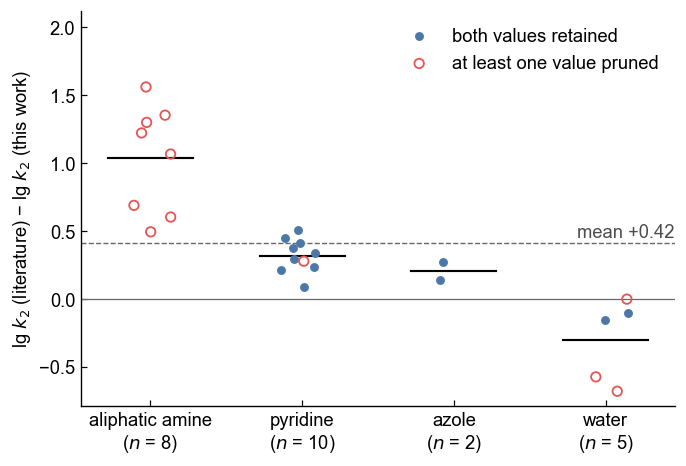

Wrote lfer_analysis_swap_offset.png


In [10]:
class_order = [c for c in ["aliphatic amine", "pyridine", "azole", "thiol", "phenol", "water"] if c in set(duplicates["nucleophile_class"])]
fig, ax = plt.subplots(figsize=(6.4, 4.4))
rng = np.random.default_rng(1)
for k, cl in enumerate(class_order):
    g = duplicates[duplicates["nucleophile_class"] == cl]
    x = k + rng.uniform(-0.15, 0.15, len(g)); kept = g["retained_in_both"].to_numpy()
    ax.scatter(x[kept], g["delta"].to_numpy()[kept], s=34, color="#4C78A8", linewidths=0, zorder=3, label="both values retained" if k == 0 else None)
    ax.scatter(x[~kept], g["delta"].to_numpy()[~kept], s=38, facecolors="none", edgecolors="#E45756", linewidths=1.2, zorder=3,
               label="at least one value pruned" if k == 0 else None)
    ax.plot([k - 0.28, k + 0.28], [g["delta"].mean()] * 2, color="k", lw=1.4, zorder=2)
ax.axhline(0, color="0.4", lw=0.8); ax.axhline(duplicates["delta"].mean(), color="0.4", lw=0.9, ls="--")
ax.text(len(class_order) - 0.55, duplicates["delta"].mean() + 0.04, f"mean {duplicates['delta'].mean():+.2f}", color="0.3", ha="right")
ax.set_xticks(range(len(class_order))); ax.set_xticklabels([f"{c}\n($n$ = {int((duplicates['nucleophile_class'] == c).sum())})" for c in class_order])
ax.set_ylabel("lg $k_2$ (literature) − lg $k_2$ (this work)")
ax.set_ylim(top=ax.get_ylim()[1] + 0.45)
ax.legend(frameon=False, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); fig.savefig(CONFIG.OFFSET_FIG_FILE, dpi=300, bbox_inches="tight"); plt.show()
print(f"Wrote {CONFIG.OFFSET_FIG_FILE}")

## 5. Source-swap refits

The selection is rerun on the two modified inputs, in which the overlapping nucleophile reactions carry the value of one
source only (the overlapping hydrolysis rate constants are not swapped). Reported are the composition of the reference system, the water
parameters, and the parameter shifts relative to the half-width of the 95 % interval of the full parametrization (the two
anchors have zero-width intervals and are excluded from the ratio; the hydrolysis-derived $E_\mathrm{P}$ values are listed
separately).

In [11]:
swap_pairs = {p for p in dup_pairs if p[0] != CONFIG.WATER_LABEL}       # overlapping nucleophile reactions only
is_lit_dup = (raw.source == CONFIG.SOURCE_LITERATURE) & pairs(raw).isin(swap_pairs)
is_own_dup = (raw.source == CONFIG.SOURCE_THIS_WORK) & pairs(raw).isin(swap_pairs)
print(f"Overlapping nucleophile reactions swapped: {len(swap_pairs)} ({int(is_lit_dup.sum())} literature values, {int(is_own_dup.sum())} values from this work); "
      f"overlapping hydrolysis reactions left unchanged: {len(dup_pairs) - len(swap_pairs)}")
variants = [full, run_selection(raw[~is_lit_dup].reset_index(drop=True), CONFIG.VARIANTS[0]),
            run_selection(raw[~is_own_dup].reset_index(drop=True), CONFIG.VARIANTS[1])]

full_nucs, full_elecs = set(full["core"]["nucleophile"]), set(full["core"]["electrophile"])
rows = []
for v in variants:
    m = v["metrics"]; cn, ce = set(v["core"]["nucleophile"]), set(v["core"]["electrophile"])
    p = _param_lookup(v["params"]); wc = v["core"][v["core"]["nucleophile"] == CONFIG.WATER_LABEL]
    rows.append(dict(variant=v["label"], n_input=v["n_input"], n_reference=m["n"], n_nucleophiles=m["n_nuc"], n_electrophiles=m["n_elec"],
                     rmse=m["rmse"], n_outliers=int((v["removed"]["reason"] == "MAD_outlier").sum()),
                     water_N=p[("nucleophile", CONFIG.WATER_LABEL, "N")], water_s=p[("nucleophile", CONFIG.WATER_LABEL, "s")],
                     water_reactions=f"{int((wc.source == CONFIG.SOURCE_THIS_WORK).sum())} this work + {int((wc.source == CONFIG.SOURCE_LITERATURE).sum())} literature",
                     species_lost=", ".join(sorted((full_nucs - cn) | (full_elecs - ce))) or "-"))
reference_systems = pd.DataFrame(rows)
print("Reference systems:")
display(reference_systems.round(3))

def parameter_table(v):
    t = pd.concat([v["params"], pd.DataFrame({"type": "electrophile", "species": v["E_hydro"].index, "parameter": "E (hydrolysis only)",
                                              "estimate": v["E_hydro"].values})], ignore_index=True)
    return t.rename(columns={"estimate": v["label"]})

param_cmp = parameter_table(full)
param_cmp["ci_half"] = [ci_half.get((t, s, q), np.nan) if q != "E (hydrolysis only)" else (hydro_ci.loc[s, "hi95"] - hydro_ci.loc[s, "lo95"]) / 2
                        for t, s, q in zip(param_cmp["type"], param_cmp["species"], param_cmp["parameter"])]
for v in variants[1:]:
    param_cmp = param_cmp.merge(parameter_table(v), on=["type", "species", "parameter"], how="left")
    param_cmp["shift: " + v["label"]] = param_cmp[v["label"]] - param_cmp[CONFIG.FULL_LABEL]
    param_cmp["shift/CI: " + v["label"]] = param_cmp["shift: " + v["label"]] / param_cmp["ci_half"].where(param_cmp["ci_half"] > 1e-9)

shift_summary = []
for v in variants[1:]:
    col, sh = "shift/CI: " + v["label"], "shift: " + v["label"]
    for fam in ("E", "E (hydrolysis only)", "N", "s"):
        q = param_cmp[(param_cmp["parameter"] == fam) & param_cmp[col].notna()]
        shift_summary.append(dict(variant=v["label"], parameter=fam, n_compared=len(q),
                                  n_not_in_variant=int(param_cmp[param_cmp["parameter"] == fam][v["label"]].isna().sum()),
                                  median_abs_shift=q[sh].abs().median(), max_abs_shift=q[sh].abs().max(), frac_within_CI=(q[col].abs() <= 1).mean(),
                                  beyond_CI=", ".join(f"{s} ({d:+.2f})" for s, d in zip(q.loc[q[col].abs() > 1, "species"], q.loc[q[col].abs() > 1, sh])) or "-"))
shift_summary = pd.DataFrame(shift_summary)
print("\nParameter shifts relative to the full parametrization (shift/CI = shift divided by the half-width of the 95 % interval):")
display(shift_summary.round(3))

Overlapping nucleophile reactions swapped: 19 (20 literature values, 19 values from this work); overlapping hydrolysis reactions left unchanged: 4
Reference systems:


,variant,n_input,n_reference,n_nucleophiles,n_electrophiles,rmse,n_outliers,water_N,water_s,water_reactions,species_lost
0,full parametrization,278,187,35,14,0.140,31,-6.353,1.066,1 this work + 15 literature,-
1,this work decides,258,172,34,14,0.128,24,-6.332,1.051,1 this work + 15 literature,4-cyanopyridine
2,literature decides,259,134,29,14,0.054,53,-6.444,1.115,1 this work + 15 literature,"2,2,2-trifluoroethylamine, 4-dimethylaminopyri..."



Parameter shifts relative to the full parametrization (shift/CI = shift divided by the half-width of the 95 % interval):


,variant,parameter,n_compared,n_not_in_variant,median_abs_shift,max_abs_shift,frac_within_CI,beyond_CI
0,this work decides,E,13,0,0.043,0.065,1.000,-
1,this work decides,E (hydrolysis only),20,0,0.010,0.109,1.000,-
2,this work decides,N,34,1,0.056,1.318,0.971,"2,2,2-trifluoroethylamine (-1.32)"
3,this work decides,s,33,1,0.018,0.308,0.970,"2,2,2-trifluoroethylamine (+0.31)"
4,literature decides,E,13,0,0.102,0.479,0.692,"P5 (-0.25), P6 (-0.42), P8 (+0.12), P9 (-0.48)"
5,literature decides,E (hydrolysis only),20,0,0.043,0.352,1.000,-
6,literature decides,N,29,6,0.118,0.457,0.517,"3-cyanopyridine (+0.26), 4-methylpyridine (+0...."
7,literature decides,s,28,6,0.052,0.325,0.714,"3-cyanopyridine (-0.07), 4-methoxypyridine (-0..."


## 6. Predicted rate constants

For every combination of species parametrized in both the full parametrization and a variant, the predicted $\lg k_2$ of
the variant is compared with that of the full parametrization, separately for combinations of species in the reference
system and for combinations with a phosphorylating agent defined by hydrolysis alone.

In [12]:
CLASSES = ("both species in reference system", "phosphorylating agent defined by hydrolysis only")

def prediction_grid(v):
    p = _param_lookup(v["params"])
    nucs = sorted({s for (t, s, q) in p if t == "nucleophile"}); elecs = sorted({s for (t, s, q) in p if t == "electrophile"})
    rows = [dict(nucleophile=n, electrophile=e, combination=CLASSES[0], lgk_pred=predict_lgk(p, n, e)) for n in nucs for e in elecs]
    rows += [dict(nucleophile=n, electrophile=e, combination=CLASSES[1], lgk_pred=p[("nucleophile", n, "N")] + p[("nucleophile", n, "s")] * E)
             for n in nucs for e, E in v["E_hydro"].items()]
    return pd.DataFrame(rows)

grid_full = prediction_grid(full)
predictions = pd.concat([grid_full.merge(prediction_grid(v), on=["nucleophile", "electrophile", "combination"], suffixes=("_full", "_variant"))
                         .assign(variant=v["label"]) for v in variants[1:]], ignore_index=True)
predictions["delta"] = predictions["lgk_pred_variant"] - predictions["lgk_pred_full"]
predictions["abs"] = predictions["delta"].abs()
prediction_summary = (predictions.groupby(["variant", "combination"], sort=False)
                      .agg(n_combinations=("delta", "size"), mean_shift=("delta", "mean"), median_abs_shift=("abs", "median"),
                           p90_abs_shift=("abs", lambda x: x.quantile(.9)), max_abs_shift=("abs", "max"),
                           frac_within_0p5=("abs", lambda x: (x <= .5).mean()), frac_within_1p0=("abs", lambda x: (x <= 1).mean()))
                      .reset_index()
                      .merge(grid_full.groupby("combination").size().rename("n_full_parametrization").reset_index(), on="combination"))
print("Change of the predicted lg k2 (variant minus full parametrization):")
display(prediction_summary.round(3))

Change of the predicted lg k2 (variant minus full parametrization):


,variant,combination,n_combinations,mean_shift,median_abs_shift,p90_abs_shift,max_abs_shift,frac_within_0p5,frac_within_1p0,n_full_parametrization
0,this work decides,both species in reference system,476,0.008,0.027,0.162,1.847,0.973,0.987,490
1,this work decides,phosphorylating agent defined by hydrolysis only,680,-0.057,0.049,0.159,3.355,0.968,0.982,700
2,literature decides,both species in reference system,406,-0.079,0.095,0.537,1.416,0.877,0.980,490
3,literature decides,phosphorylating agent defined by hydrolysis only,580,0.122,0.102,0.470,2.265,0.903,0.988,700


### Figure: parameter shifts and prediction shifts

Left: shifts of the reactivity parameters relative to the full parametrization in units of the half-width of its 95 %
interval (points beyond ±5 are drawn at the edge and labeled). Middle and right: changes of the predicted $\lg k_2$.

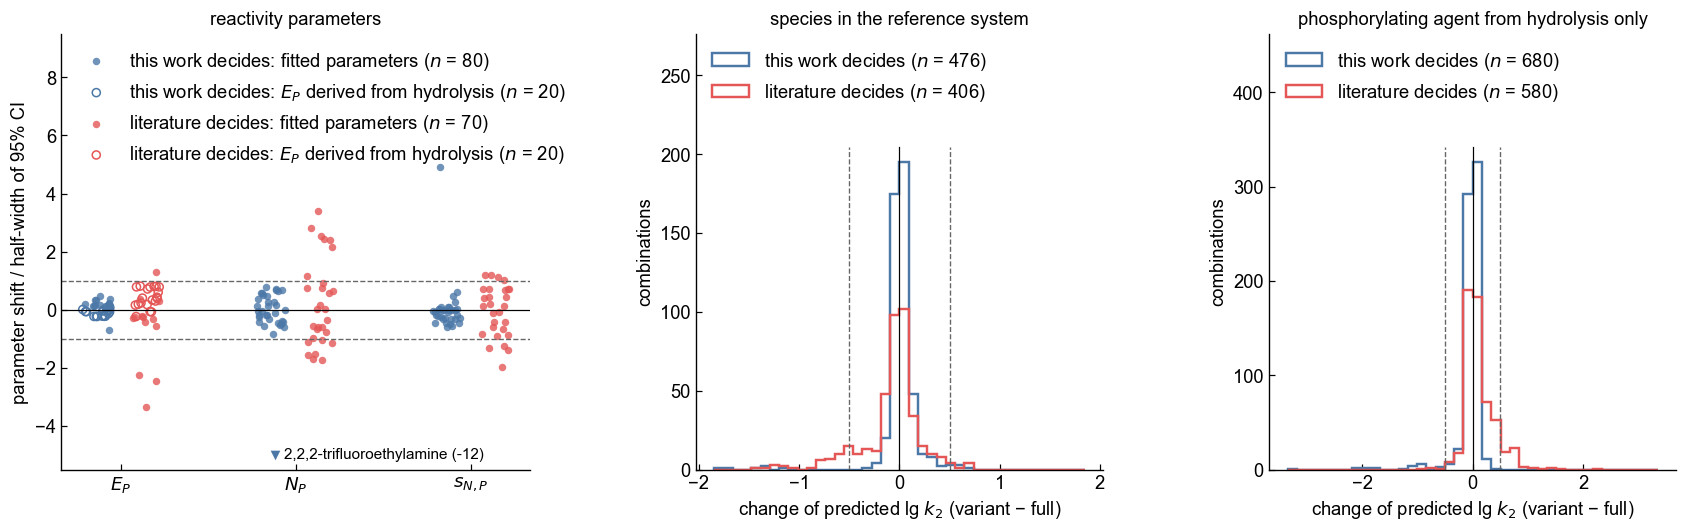

Wrote lfer_analysis_swap_parameters.png


In [13]:
colors = dict(zip(CONFIG.VARIANTS, ("#4C78A8", "#E45756")))
fig, ax = plt.subplots(1, 3, figsize=(15.5, 5.0), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))

# left: parameter shifts in units of the 95 % interval half-width
rng = np.random.default_rng(0); fam_pos = {"E": 0, "E (hydrolysis only)": 0, "N": 1, "s": 2}
Y_CLIP = 5.0   # shifts beyond +-5 interval half-widths are drawn at the edge of the panel
for k, v in enumerate(variants[1:]):
    col = "shift/CI: " + v["label"]; q = param_cmp[param_cmp[col].notna()]
    x = q["parameter"].map(fam_pos).to_numpy(float) + (k - 0.5) * 0.28 + rng.uniform(-0.08, 0.08, len(q))
    y = q[col].to_numpy(); hyd = (q["parameter"] == "E (hydrolysis only)").to_numpy(); out = np.abs(y) > Y_CLIP
    ax[0].scatter(x[~hyd & ~out], y[~hyd & ~out], s=24, alpha=0.8, color=colors[v["label"]], linewidths=0,
                  label=f"{v['label']}: fitted parameters ($n$ = {int((~hyd).sum())})")
    ax[0].scatter(x[hyd & ~out], y[hyd & ~out], s=28, facecolors="none", edgecolors=colors[v["label"]], linewidths=1.0,
                  label=f"{v['label']}: $E_P$ derived from hydrolysis ($n$ = {int(hyd.sum())})")
    for xo, yo, sp in zip(x[out], y[out], q["species"].to_numpy()[out]):
        ax[0].scatter(xo, np.sign(yo) * Y_CLIP, s=40, marker="v" if yo < 0 else "^", color=colors[v["label"]], linewidths=0)
        ax[0].annotate(f"{sp} ({yo:+.0f})", (xo, np.sign(yo) * Y_CLIP), xytext=(6, 0), textcoords="offset points", va="center", fontsize=FONTSIZE - 2)
for y in (-1, 1):
    ax[0].axhline(y, color="0.4", ls="--", lw=0.9)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xticks([0, 1, 2]); ax[0].set_xticklabels(["$E_P$", "$N_P$", "$s_{N,P}$"])
ax[0].set_ylim(-Y_CLIP - 0.5, Y_CLIP + 4.5)                 # headroom for the legend
ax[0].set_ylabel("parameter shift / half-width of 95% CI"); ax[0].set_title("reactivity parameters")
ax[0].legend(frameon=False, loc="upper left")

# middle and right: prediction shifts
for a_, cls, title in zip(ax[1:], CLASSES, ("species in the reference system", "phosphorylating agent from hydrolysis only")):
    sub = predictions[predictions["combination"] == cls]
    lim = max(1.0, sub["abs"].max()); bins = np.linspace(-lim, lim, 41)
    for v in variants[1:]:
        g = sub[sub["variant"] == v["label"]]
        a_.hist(g["delta"], bins=bins, histtype="step", lw=1.6, color=colors[v["label"]], label=f"{v['label']} ($n$ = {len(g)})")
    y_bars = a_.get_ylim()[1]
    a_.set_ylim(0, 1.35 * y_bars)                       # headroom so the legend sits above the bars
    a_.plot([0, 0], [0, y_bars], color="k", lw=0.8)
    for xx in (-0.5, 0.5):
        a_.plot([xx, xx], [0, y_bars], color="0.4", ls="--", lw=0.9)
    a_.set_xlabel("change of predicted lg $k_2$ (variant − full)"); a_.set_ylabel("combinations"); a_.set_title(title)
    a_.legend(frameon=False, loc="upper left")
for a_ in ax:
    for side in ("top", "right"):
        a_.spines[side].set_visible(False)
plt.tight_layout(); fig.savefig(CONFIG.SWAP_FIG_FILE, dpi=300, bbox_inches="tight"); plt.show()
print(f"Wrote {CONFIG.SWAP_FIG_FILE}")

## 7. Export

In [14]:
with pd.ExcelWriter(CONFIG.RESULTS_FILE) as xw:
    pd.DataFrame({"item": ["input", "raw sheet", "reference sheet", "n_raw", "n_reference", "n_nucleophiles", "n_electrophiles", "rmse",
                           "anchor_nucleophile", "anchor_electrophile", "min_electrophiles_per_nucleophile", "min_nucleophiles_per_electrophile",
                           "outlier_mad_k", "n_duplicated_reactions", "n_overlapping_literature_values", "mean_offset_lit_minus_this_work"],
                  "value": [CONFIG.V2_METADATA_FILE, CONFIG.RAW_SHEET, CONFIG.REFERENCE_SHEET, len(raw), m["n"], m["n_nuc"], m["n_elec"], m["rmse"],
                            CONFIG.ANCHOR_NUC, CONFIG.ANCHOR_ELEC, CONFIG.MIN_ELECTROPHILES, CONFIG.MIN_NUC_PER_ELEC, CONFIG.OUTLIER_MAD_K,
                            len(dup_pairs), len(duplicates), duplicates["delta"].mean()]}).to_excel(xw, sheet_name="README", index=False)
    duplicates.to_excel(xw, sheet_name="duplicates", index=False)
    offset_summary.to_excel(xw, sheet_name="offset_by_class", index=False)
    source_bias.to_excel(xw, sheet_name="source_bias", index=False)
    reference_systems.to_excel(xw, sheet_name="reference_systems", index=False)
    shift_summary.to_excel(xw, sheet_name="parameter_shift_summary", index=False)
    param_cmp.sort_values(["type", "parameter", "species"]).to_excel(xw, sheet_name="parameters", index=False)
    prediction_summary.to_excel(xw, sheet_name="prediction_shift_summary", index=False)
    predictions.sort_values("abs", ascending=False).to_excel(xw, sheet_name="predictions", index=False)
    for v in variants:
        v["removed"].to_excel(xw, sheet_name="removed_" + v["label"].replace(" ", "_")[:23], index=False)
print(f"Wrote {CONFIG.RESULTS_FILE}")

Wrote lfer_analysis_swap_results.xlsx
